# Test IPR-kernel SVM experiments

This notebook tests `run_iprkernel_svm.py`.


In [1]:
from pathlib import Path
import importlib
import sys

import pandas as pd

cwd = Path.cwd()
script_dir = cwd if (cwd / "run_iprkernel_svm.py").exists() else cwd / "scripts"
if str(script_dir) not in sys.path:
    sys.path.insert(0, str(script_dir))

import run_iprkernel_svm as svm_runner
importlib.reload(svm_runner)

from data_config import available_l_values
from run_iprkernel_svm import run_iprkernel_svm_experiment

# print("Using:", svm_runner.__file__)
%matplotlib inline

## Current workflow

For each dataset and system size `L`, the script builds an IPR-kernel Gram matrix from raw processed IPR features, splits the Gram matrix into train/test blocks, and fits `SVC(kernel="precomputed")`.

The reported metric is balanced accuracy only:

- global balanced accuracy: test points sampled from the full parameter range
- local balanced accuracy: test points sampled inside a window around the phase boundary


## SVM process

1. Load the processed raw IPR curves for one dataset and one system size `L`.
2. Build one feature vector per parameter point, for example `[IPR X, IPR Z]`.
3. Compute the IPR Gram matrix `K`, where each entry is the kernel value between two parameter points.
4. Assign binary phase labels by comparing the parameter to the critical point: label `0` for `h < h_c` and label `1` for `h >= h_c`. For Heisenberg, use `Delta < Delta_c` and `Delta >= Delta_c`.
5. Choose balanced test indices, either globally from the full range or locally near the phase boundary.
6. Split the precomputed kernel into `K_train = train x train` and `K_test = test x train`.
7. Train `SVC(kernel="precomputed", class_weight="balanced")` and report balanced accuracy.
8. Repeat over random splits and average the balanced accuracy for each `L`.


## Dataset notes

- `tfim1d`: TFIM 1D, parameter `h`, critical point `h_c = 1.0`.
- `tfim2d`: TFIM 2D, parameter `h`, critical point `h_c = 3.04433`.
- `heisenberg`: Heisenberg, parameter `Delta`, critical point `Delta_c = 1.0`.

The examples below use `basis=("IPR X", "IPR Z")`. For Heisenberg, `"IPR XY"` is also available as a basis component.


In [2]:
def svm_score_table(results):
    """Return a compact balanced-accuracy summary table."""
    return pd.DataFrame(
        {
            "L": results["L"],
            "global_bal_acc_mean": results["global_bal_acc_mean"],
            "global_bal_acc_std": results["global_bal_acc_std"],
            "local_bal_acc_mean": results["local_bal_acc_mean"],
            "local_bal_acc_std": results["local_bal_acc_std"],
        }
    )


for dataset in ["tfim1d", "tfim2d", "heisenberg"]:
    print(dataset, available_l_values(dataset)[:8])

tfim1d [3, 4, 5, 6, 7, 8, 9, 10]
tfim2d [3, 4, 5, 6, 7, 8, 9, 10]
heisenberg [6, 8, 10, 12, 14, 16, 18, 20]


## TFIM 1D example


GLOBAL experiment:
L=10: balanced accuracy = 1.0000 +/- 0.0000
L=20: balanced accuracy = 1.0000 +/- 0.0000
L=30: balanced accuracy = 1.0000 +/- 0.0000
L=40: balanced accuracy = 1.0000 +/- 0.0000
L=50: balanced accuracy = 1.0000 +/- 0.0000
L=60: balanced accuracy = 1.0000 +/- 0.0000
L=70: balanced accuracy = 1.0000 +/- 0.0000
L=80: balanced accuracy = 1.0000 +/- 0.0000
L=90: balanced accuracy = 1.0000 +/- 0.0000
L=100: balanced accuracy = 1.0000 +/- 0.0000

LOCAL experiment:
L=10: balanced accuracy = 0.9875 +/- 0.0000
L=20: balanced accuracy = 1.0000 +/- 0.0000
L=30: balanced accuracy = 0.9950 +/- 0.0000
L=40: balanced accuracy = 0.9950 +/- 0.0000
L=50: balanced accuracy = 0.9975 +/- 0.0000
L=60: balanced accuracy = 0.9975 +/- 0.0000
L=70: balanced accuracy = 0.9975 +/- 0.0000
L=80: balanced accuracy = 0.9925 +/- 0.0000
L=90: balanced accuracy = 0.9975 +/- 0.0000
L=100: balanced accuracy = 0.9975 +/- 0.0000


,L,global_bal_acc_mean,global_bal_acc_std,local_bal_acc_mean,local_bal_acc_std
0,10,1.0,0.0,0.9875,0.0
1,20,1.0,0.0,1.0000,0.0
2,30,1.0,0.0,0.9950,0.0
3,40,1.0,0.0,0.9950,0.0
4,50,1.0,0.0,0.9975,0.0
5,60,1.0,0.0,0.9975,0.0
6,70,1.0,0.0,0.9975,0.0
7,80,1.0,0.0,0.9925,0.0
8,90,1.0,0.0,0.9975,0.0
9,100,1.0,0.0,0.9975,0.0


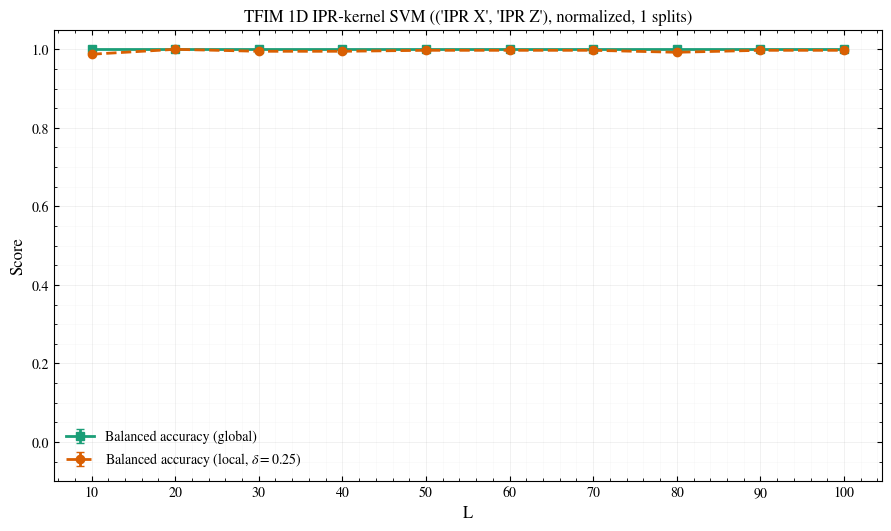

In [3]:
fig, ax, tfim1d_results = run_iprkernel_svm_experiment(
    dataset="tfim1d",
    L_values=[10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
    basis=("IPR X", "IPR Z"),
    test_frac=0.10,
    local_delta=0.25,
    n_splits=1,
    rng_seed=12345,
    use_normalized_kernel=True,
    C=1.0,
    make_plot=True,
    print_report=True,
)

svm_score_table(tfim1d_results)

## TFIM 2D example


GLOBAL experiment:
L=3: balanced accuracy = 0.9550 +/- 0.0000
L=4: balanced accuracy = 0.9350 +/- 0.0000
L=5: balanced accuracy = 0.9300 +/- 0.0000
L=6: balanced accuracy = 0.9300 +/- 0.0000
L=7: balanced accuracy = 0.9325 +/- 0.0000
L=8: balanced accuracy = 0.9350 +/- 0.0000
L=9: balanced accuracy = 0.9325 +/- 0.0000
L=10: balanced accuracy = 0.9350 +/- 0.0000

LOCAL experiment:
L=3: balanced accuracy = 0.5000 +/- 0.0000
L=4: balanced accuracy = 0.5000 +/- 0.0000
L=5: balanced accuracy = 0.5000 +/- 0.0000
L=6: balanced accuracy = 0.5000 +/- 0.0000
L=7: balanced accuracy = 0.5000 +/- 0.0000
L=8: balanced accuracy = 0.5000 +/- 0.0000
L=9: balanced accuracy = 0.5000 +/- 0.0000
L=10: balanced accuracy = 0.5000 +/- 0.0000


,L,global_bal_acc_mean,global_bal_acc_std,local_bal_acc_mean,local_bal_acc_std
0,3,0.9550,0.0,0.5,0.0
1,4,0.9350,0.0,0.5,0.0
2,5,0.9300,0.0,0.5,0.0
3,6,0.9300,0.0,0.5,0.0
4,7,0.9325,0.0,0.5,0.0
5,8,0.9350,0.0,0.5,0.0
6,9,0.9325,0.0,0.5,0.0
7,10,0.9350,0.0,0.5,0.0


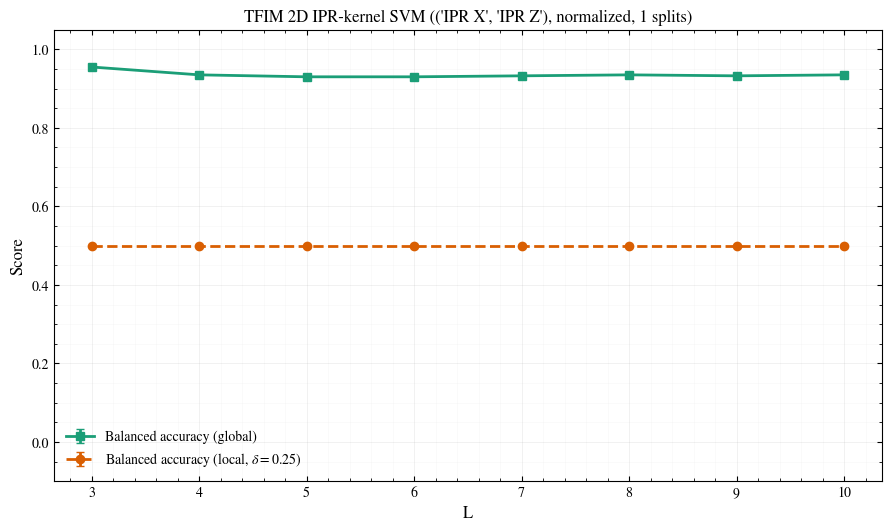

In [4]:
fig, ax, tfim2d_results = run_iprkernel_svm_experiment(
    dataset="tfim2d",
    L_values=[3, 4, 5, 6, 7, 8, 9, 10],
    basis=("IPR X", "IPR Z"),
    test_frac=0.10,
    local_delta=0.25,
    n_splits=1,
    rng_seed=12345,
    use_normalized_kernel=True,
    C=1.0,
    make_plot=True,
    print_report=True,
)

svm_score_table(tfim2d_results)

## Heisenberg example


GLOBAL experiment:
L=6: balanced accuracy = 0.9900 +/- 0.0000
L=8: balanced accuracy = 0.9920 +/- 0.0000
L=10: balanced accuracy = 0.9940 +/- 0.0000
L=12: balanced accuracy = 0.9960 +/- 0.0000
L=14: balanced accuracy = 0.9960 +/- 0.0000
L=16: balanced accuracy = 0.9980 +/- 0.0000
L=18: balanced accuracy = 0.9980 +/- 0.0000
L=20: balanced accuracy = 0.9980 +/- 0.0000
L=22: balanced accuracy = 0.9980 +/- 0.0000
L=24: balanced accuracy = 0.9980 +/- 0.0000

LOCAL experiment:
L=6: balanced accuracy = 0.9600 +/- 0.0000
L=8: balanced accuracy = 0.9760 +/- 0.0000
L=10: balanced accuracy = 0.9800 +/- 0.0000
L=12: balanced accuracy = 0.9820 +/- 0.0000
L=14: balanced accuracy = 0.9840 +/- 0.0000
L=16: balanced accuracy = 0.9840 +/- 0.0000
L=18: balanced accuracy = 0.9860 +/- 0.0000
L=20: balanced accuracy = 0.9880 +/- 0.0000
L=22: balanced accuracy = 0.9900 +/- 0.0000
L=24: balanced accuracy = 0.9900 +/- 0.0000


,L,global_bal_acc_mean,global_bal_acc_std,local_bal_acc_mean,local_bal_acc_std
0,6,0.990,0.0,0.960,0.0
1,8,0.992,0.0,0.976,0.0
2,10,0.994,0.0,0.980,0.0
3,12,0.996,0.0,0.982,0.0
4,14,0.996,0.0,0.984,0.0
5,16,0.998,0.0,0.984,0.0
6,18,0.998,0.0,0.986,0.0
7,20,0.998,0.0,0.988,0.0
8,22,0.998,0.0,0.990,0.0
9,24,0.998,0.0,0.990,0.0


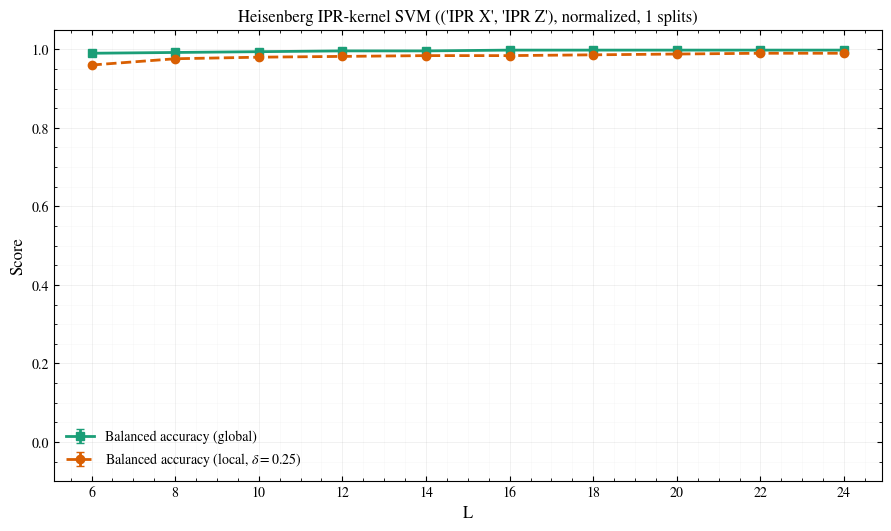

In [5]:
fig, ax, heisenberg_results = run_iprkernel_svm_experiment(
    dataset="heisenberg",
    L_values=[6, 8, 10, 12, 14, 16, 18, 20, 22, 24],
    basis=("IPR X", "IPR Z"),
    test_frac=0.10,
    local_delta=0.25,
    n_splits=1,
    rng_seed=12345,
    use_normalized_kernel=True,
    C=1.0,
    make_plot=True,
    print_report=True,
)

svm_score_table(heisenberg_results)

GLOBAL experiment:
L=6: balanced accuracy = 0.9540 +/- 0.0000
L=8: balanced accuracy = 0.9500 +/- 0.0000
L=10: balanced accuracy = 0.9440 +/- 0.0000
L=12: balanced accuracy = 0.9360 +/- 0.0000
L=14: balanced accuracy = 0.9260 +/- 0.0000
L=16: balanced accuracy = 0.9200 +/- 0.0000
L=18: balanced accuracy = 0.9160 +/- 0.0000
L=20: balanced accuracy = 0.9120 +/- 0.0000
L=22: balanced accuracy = 0.9080 +/- 0.0000
L=24: balanced accuracy = 0.9040 +/- 0.0000

LOCAL experiment:
L=6: balanced accuracy = 0.5960 +/- 0.0000
L=8: balanced accuracy = 0.5000 +/- 0.0000
L=10: balanced accuracy = 0.5000 +/- 0.0000
L=12: balanced accuracy = 0.5000 +/- 0.0000
L=14: balanced accuracy = 0.5000 +/- 0.0000
L=16: balanced accuracy = 0.5000 +/- 0.0000
L=18: balanced accuracy = 0.5000 +/- 0.0000
L=20: balanced accuracy = 0.5000 +/- 0.0000
L=22: balanced accuracy = 0.5000 +/- 0.0000
L=24: balanced accuracy = 0.5000 +/- 0.0000


,L,global_bal_acc_mean,global_bal_acc_std,local_bal_acc_mean,local_bal_acc_std
0,6,0.954,0.0,0.596,0.0
1,8,0.950,0.0,0.500,0.0
2,10,0.944,0.0,0.500,0.0
3,12,0.936,0.0,0.500,0.0
4,14,0.926,0.0,0.500,0.0
5,16,0.920,0.0,0.500,0.0
6,18,0.916,0.0,0.500,0.0
7,20,0.912,0.0,0.500,0.0
8,22,0.908,0.0,0.500,0.0
9,24,0.904,0.0,0.500,0.0


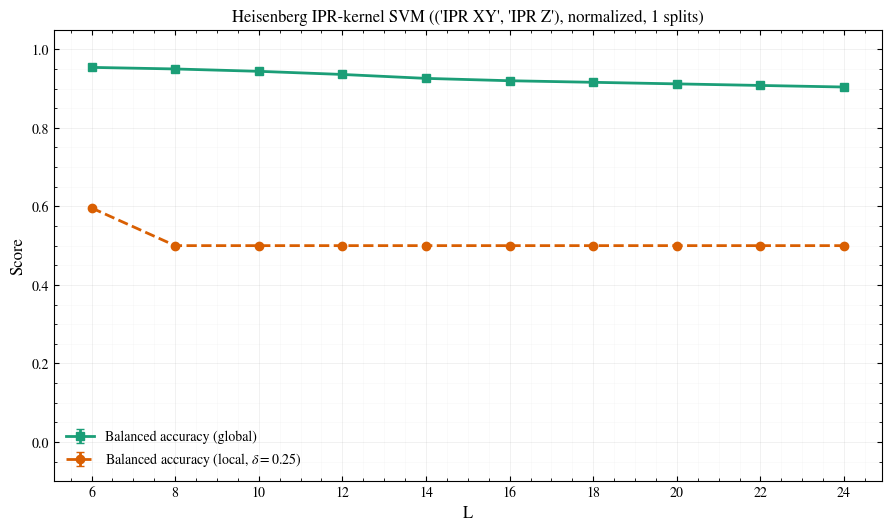

In [6]:
fig, ax, heisenberg_results = run_iprkernel_svm_experiment(
    dataset="heisenberg",
    L_values=[6, 8, 10, 12, 14, 16, 18, 20, 22, 24],
    basis=("IPR XY", "IPR Z"),
    test_frac=0.10,
    local_delta=0.25,
    n_splits=1,
    rng_seed=12345,
    use_normalized_kernel=True,
    C=1.0,
    make_plot=True,
    print_report=True,
)

svm_score_table(heisenberg_results)